# AgroPredix · Motor experto (difuso + bayesiano)

In [ ]:
# ============ PARÁMETROS (puedes cambiarlos) ============
DISTRITOS = ['TIABAYA', 'SACHACA', 'UCHUMAYO']      # alcance de la tesis
N_CULTIVOS = 10                                     # catálogo de la tesis
CULTIVOS_MANUAL = None                              # ej.: ['CEBOLLA', 'AJO', ...] para fijar el catálogo a mano
FECHA_INI, FECHA_FIN = '20150801', '20260531'       # mismo periodo que el SISAGRI

# Ajuste bayesiano (RF-0006)
K_PRIOR = 8                  # "fuerza" del prior regional, en campañas equivalentes
UMBRAL_EXITO = 1.0           # una campaña es exitosa si rinde >= esta fracción de la mediana regional del cultivo
                             # (con 0.8 casi todas las campañas son 'exitosas' y la certeza deja de discriminar)
PENALIZACION_FALTANTE = 0.15 # cuánto baja la certeza por cada dato de entrada que falta
MIN_FACTOR_DATOS = 0.40      # piso del factor de completitud

SEED = 42

In [ ]:
import os, re, json, math, time, unicodedata, warnings, urllib.parse, urllib.request
from datetime import date
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUERIDOS = ['sisagri_arequipa_completo.csv', 'suelos_arequipa_distritos_completo.csv',
              'coordenadas_distritos.csv', 'requisitos_cultivos.csv']
faltan = [f for f in REQUERIDOS if not os.path.exists(f)]
if faltan and IN_COLAB:
    print('Sube estos archivos:', faltan)
    files.upload()
    faltan = [f for f in REQUERIDOS if not os.path.exists(f)]
assert not faltan, f'Faltan archivos: {faltan}'
print('Archivos listos ✔')

Archivos listos ✔


## Paso 1 · Cargar y validar los datos

In [ ]:
sis = pd.read_csv('sisagri_arequipa_completo.csv', encoding='utf-8-sig')
suelo = pd.read_csv('suelos_arequipa_distritos_completo.csv')
coords = pd.read_csv('coordenadas_distritos.csv')
req = pd.read_csv('requisitos_cultivos.csv', encoding='utf-8-sig')

for c in ['SIEMBRA', 'COSECHA', 'PRODUCCION', 'VERDE_ACTUAL', 'PRECIO_CHACRA']:
    sis[c] = pd.to_numeric(sis[c], errors='coerce')
sis[['SIEMBRA', 'COSECHA', 'PRODUCCION']] = sis[['SIEMBRA', 'COSECHA', 'PRODUCCION']].fillna(0)

# campaña agrícola: agosto-julio (se identifica por su año de inicio)
sis['camp_ini'] = np.where(sis['MES'] >= 8, sis['AÑO'], sis['AÑO'] - 1)
meses_por_camp = sis.groupby('camp_ini')[['AÑO', 'MES']].apply(lambda x: len(x.drop_duplicates()))
CAMP_COMPLETAS = sorted(meses_por_camp[meses_por_camp == 12].index.tolist())

ub = (sis[sis['DISTRITO'].isin(DISTRITOS)][['DISTRITO', 'COD_UBIGEO']].drop_duplicates()
      .set_index('DISTRITO')['COD_UBIGEO'].to_dict())
assert set(ub) == set(DISTRITOS), f'No se encontraron todos los distritos: {ub}'

_ym = sis['AÑO'] * 100 + sis['MES']
print(f'SISAGRI Arequipa: {len(sis):,} filas | periodo {_ym.min() // 100}-{_ym.min() % 100:02d} a {_ym.max() // 100}-{_ym.max() % 100:02d}')
print('Campañas completas (inicio):', CAMP_COMPLETAS)
print('Distritos de la tesis:', ub)
assert suelo[suelo['cod_ubigeo'].isin(ub.values())][['clay', 'phh2o']].notna().all().all(), 'Falta suelo en algún distrito'
print('Suelo disponible para los 3 distritos ✔')

SISAGRI Arequipa: 148,143 filas | periodo 2015-08 a 2026-05
Campañas completas (inicio): [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Distritos de la tesis: {'SACHACA': 40117, 'TIABAYA': 40123, 'UCHUMAYO': 40124}
Suelo disponible para los 3 distritos ✔


## Paso 2 · Clima diario (NASA POWER) y climatología mensual
Descarga el clima de los 3 distritos (3 consultas). Si NASA POWER no responde, usa el archivo de respaldo 2015-2018 (menos datos, pero el notebook sigue funcionando).

In [ ]:
NASA_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'
PARAMS = {'T2M_MAX': 'tmax', 'T2M_MIN': 'tmin', 'PRECTOTCORR': 'prec', 'RH2M': 'hr'}


def descargar_nasa(lat, lon, ini, fin, reintentos=3):
    q = urllib.parse.urlencode(dict(parameters=','.join(PARAMS), community='AG', latitude=round(lat, 4),
                                    longitude=round(lon, 4), start=ini, end=fin, format='JSON'))
    for i in range(reintentos):
        try:
            with urllib.request.urlopen(f'{NASA_URL}?{q}', timeout=120) as r:
                par = json.load(r)['properties']['parameter']
            df = pd.DataFrame({PARAMS[k]: pd.Series(par[k]) for k in PARAMS})
            df.index.name = 'fecha'
            df = df.reset_index()
            for c in PARAMS.values():
                df[c] = pd.to_numeric(df[c], errors='coerce').where(lambda s: s > -990)
            return df
        except Exception as e:
            print(f'   intento {i + 1}/{reintentos} falló: {e.__class__.__name__}')
            time.sleep(5 * (i + 1))
    return None


CACHE = 'clima_3distritos.csv'
if os.path.exists(CACHE):
    clima = pd.read_csv(CACHE)
    print('Clima leído de caché:', CACHE)
else:
    partes = []
    if os.environ.get('AGROPREDIX_OFFLINE') != '1':
        for dist, cod in ub.items():
            fila = coords[coords['cod_ubigeo'] == cod].iloc[0]
            print(f'Descargando clima de {dist} ...')
            df = descargar_nasa(fila['latitud'], fila['longitud'], FECHA_INI, FECHA_FIN)
            if df is None:
                partes = []
                break
            df.insert(0, 'distrito', dist)
            partes.append(df)
    if partes:
        clima = pd.concat(partes, ignore_index=True)
        clima.to_csv(CACHE, index=False)
        print('Clima descargado de NASA POWER ✔')
    else:
        resp = 'clima_arequipa_nasa_power_2015_2018.csv'
        assert os.path.exists(resp), 'NASA POWER no respondió y no subiste el archivo de respaldo.'
        print('⚠️ NASA POWER no respondió: usando el respaldo 2015-2018.')
        r = pd.read_csv(resp)
        r = r[r['cod_ubigeo'].isin(ub.values())].copy()
        r['distrito'] = r['cod_ubigeo'].map({v: k for k, v in ub.items()})
        clima = r.rename(columns={'temp_max': 'tmax', 'temp_min': 'tmin', 'precipitacion': 'prec',
                                  'humedad_relativa': 'hr'})[['distrito', 'fecha', 'tmax', 'tmin', 'prec', 'hr']]

clima['fecha'] = pd.to_datetime(clima['fecha'].astype(str), format='%Y%m%d')
clima['anio'], clima['mes'] = clima['fecha'].dt.year, clima['fecha'].dt.month
clima['tmedia'] = (clima['tmax'] + clima['tmin']) / 2
print(f'Clima: {clima["fecha"].min().date()} a {clima["fecha"].max().date()} | {clima["distrito"].nunique()} distritos | nulos: {int(clima[["tmax","tmin"]].isna().sum().sum())}')

# climatología mensual por distrito (promedio de todos los años) y probabilidad de helada
clim_mes = (clima.groupby(['distrito', 'mes'])
            .agg(temp_media=('tmedia', 'mean'), temp_max=('tmax', 'mean'), temp_min=('tmin', 'mean'))
            .reset_index())
helada = (clima.assign(h=(clima['tmin'] <= 0)).groupby(['distrito', 'anio', 'mes'])['h'].max()
          .groupby(['distrito', 'mes']).mean().rename('p_helada').reset_index())
clim_mes = clim_mes.merge(helada, on=['distrito', 'mes'])
display(clim_mes.pivot(index='mes', columns='distrito', values='temp_media').round(1))

Descargando clima de SACHACA ...
Descargando clima de TIABAYA ...
Descargando clima de UCHUMAYO ...
Clima descargado de NASA POWER ✔
Clima: 2015-08-01 a 2026-05-31 | 3 distritos | nulos: 0


distrito,SACHACA,TIABAYA,UCHUMAYO
mes,,,
1,18.4,18.4,18.4
2,18.7,18.7,18.7
3,18.5,18.5,18.5
4,18.0,18.0,18.0
5,17.3,17.3,17.3
6,16.1,16.1,16.1
7,16.2,16.2,16.2
8,16.3,16.3,16.3
9,17.0,17.0,17.0


## Paso 3 · Catálogo de 10 cultivos
Los 10 cultivos de mayor superficie sembrada acumulada en los 3 distritos (SISAGRI).

In [ ]:
tres = sis[sis['DISTRITO'].isin(DISTRITOS)]
rank = (tres.groupby(['COD_PRODUCTO', 'PRODUCTO'])['SIEMBRA'].sum().sort_values(ascending=False).reset_index())
rank['% del total'] = (rank['SIEMBRA'] / rank['SIEMBRA'].sum() * 100).round(1)

if CULTIVOS_MANUAL:
    cat = rank[rank['PRODUCTO'].isin(CULTIVOS_MANUAL)].copy()
else:
    cat = rank.head(N_CULTIVOS).copy()
assert cat['COD_PRODUCTO'].isin(req['COD_PRODUCTO']).all(), 'Hay cultivos sin requisitos en requisitos_cultivos.csv'
cat = cat.merge(req, on=['COD_PRODUCTO'], suffixes=('', '_req'))


def nombre_corto(p):
    return re.sub(r'\s*\(.*?\)', '', p).strip().title()


cat['nombre'] = cat['PRODUCTO'].map(nombre_corto)
print(f'Catálogo ({len(cat)} cultivos) — por superficie sembrada acumulada:')
display(cat[['COD_PRODUCTO', 'nombre', 'SIEMBRA', '% del total', 'tipo']])
print('Cultivos que siguen en la lista siguiente (por si el panel quiere cambiar alguno):')
display(rank.iloc[len(cat):len(cat) + 5][['PRODUCTO', 'SIEMBRA']])

Catálogo (10 cultivos) — por superficie sembrada acumulada:


,COD_PRODUCTO,nombre,SIEMBRA,% del total,tipo
0,14030100000,Cebolla,15295.0,26.8,hortaliza
1,14050060000,Maiz Chala,9057.0,15.9,forraje
2,14030030000,Ajo,7560.0,13.3,hortaliza
3,14040090000,Papa,4995.0,8.8,raiz_tuberculo
4,14030220000,Zanahoria,4753.0,8.3,hortaliza
5,14030050000,Arveja Grano Verde,3612.0,6.3,leguminosa
6,14030370000,Haba Grano Verde,1362.0,2.4,leguminosa
7,12010010000,Alfalfa,1307.0,2.3,forraje
8,14030060000,Apio,1087.0,1.9,hortaliza
9,14030360000,Frijol Vainita,842.0,1.5,leguminosa


Cultivos que siguen en la lista siguiente (por si el panel quiere cambiar alguno):


,PRODUCTO,SIEMBRA
10,LECHUGA,740.0
11,COLIFLOR,721.0
12,BETARRAGA,695.0
13,PORO,683.0
14,CEBADA FORRAJERA,626.0


## Paso 4 · Insumos del modelo: suelo, historial de éxito y calendario de siembra
- **Suelo** (SoilGrids, 0-30 cm) por distrito.
- **Éxito histórico** (RF-0006): por campaña, un cultivo es *exitoso* si su rendimiento (producción/cosecha) ≥ `UMBRAL_EXITO` × la mediana regional de ese cultivo en toda Arequipa (por defecto 1.0 = al menos la mediana). Es el dato del ajuste Beta-Binomial. *Esta definición de «éxito» es una decisión de diseño: confírmala con tu asesor.*
- **Calendario de siembra**: qué tan típico es sembrar cada cultivo en cada mes en cada distrito (datos estacionales).

In [ ]:
# ---- suelo por distrito ----
suelo3 = suelo[suelo['cod_ubigeo'].isin(ub.values())].copy()
suelo3['distrito'] = suelo3['cod_ubigeo'].map({v: k for k, v in ub.items()})
display(suelo3[['distrito', 'clay', 'sand', 'silt', 'phh2o', 'nitrogen', 'soc']].round(2))

# ---- éxito histórico por campaña (RF-0006) ----
comp = sis[sis['camp_ini'].isin(CAMP_COMPLETAS)]
camp = (comp.groupby(['DISTRITO', 'COD_PRODUCTO', 'camp_ini'])
        .agg(prod=('PRODUCCION', 'sum'), cos=('COSECHA', 'sum')).reset_index())
camp = camp[(camp['cos'] > 0) & (camp['prod'] > 0)].copy()
camp['rend'] = camp['prod'] / camp['cos']
rend_med = camp.groupby('COD_PRODUCTO')['rend'].median().rename('rend_med')
camp = camp.merge(rend_med, on='COD_PRODUCTO')
camp['exito'] = (camp['rend'] >= UMBRAL_EXITO * camp['rend_med']).astype(int)

prior_reg = camp.groupby('COD_PRODUCTO')['exito'].mean()
hist = (camp[camp['DISTRITO'].isin(DISTRITOS)].groupby(['DISTRITO', 'COD_PRODUCTO'])['exito']
        .agg(exitos='sum', n='count'))
resumen = (hist.reset_index().merge(cat[['COD_PRODUCTO', 'nombre']], on='COD_PRODUCTO')
           .pivot(index='nombre', columns='DISTRITO', values='n').fillna(0).astype(int))
print('Campañas con dato (de 10 posibles) por cultivo y distrito:')
display(resumen)

# ---- calendario de siembra: qué tan típico es sembrar en cada mes ----
cal = (comp.groupby(['DISTRITO', 'COD_PRODUCTO', 'MES'])['SIEMBRA'].sum().unstack(fill_value=0)
       .reindex(columns=range(1, 13), fill_value=0))
ratio = cal.div(cal.max(axis=1).replace(0, np.nan), axis=0).fillna(0)   # 1 = mes de mayor siembra

,distrito,clay,sand,silt,phh2o,nitrogen,soc
14,SACHACA,12.78,63.42,23.8,7.9,1.45,11.10
19,TIABAYA,11.90,66.37,21.8,8.0,1.03,9.25
20,UCHUMAYO,13.30,65.08,21.6,7.8,1.22,15.42


Campañas con dato (de 10 posibles) por cultivo y distrito:


DISTRITO,SACHACA,TIABAYA,UCHUMAYO
nombre,,,
Ajo,10,10,10
Alfalfa,10,10,10
Apio,10,10,10
Arveja Grano Verde,10,10,10
Cebolla,10,10,10
Frijol Vainita,0,10,10
Haba Grano Verde,10,10,10
Maiz Chala,10,10,10
Papa,10,10,10


## Paso 5 · Conocimiento experto (BORRADOR para validar con el panel)
Se generan **archivos editables**: familias botánicas, matriz de rotación y reglas SI-ENTONCES. Tu panel de agrónomos debe revisarlos; si los editas, vuelve a subirlos y vuelve a ejecutar el notebook.

In [ ]:
# ---- familias botánicas (hecho botánico; sirve para la rotación) ----
FAMILIAS = {
 'ALFALFA': 'Fabaceae', 'HIGUERA': 'Moraceae', 'MANZANO': 'Rosaceae', 'MELOCOTONERO': 'Rosaceae', 'OLIVO': 'Oleaceae',
 'PALTO': 'Lauraceae', 'PERAL': 'Rosaceae', 'VID': 'Vitaceae', 'ACHITA, KIWICHA, O AMARANTO': 'Amaranthaceae',
 'ARROZ': 'Poaceae', 'CEBADA GRANO': 'Poaceae', 'MAIZ AMARILLO DURO': 'Poaceae', 'MAIZ AMILACEO': 'Poaceae',
 'QUINUA': 'Amaranthaceae', 'TRIGO BLANDO': 'Poaceae', 'SANDIA': 'Cucurbitaceae', 'ACELGA': 'Amaranthaceae',
 'AJO': 'Amaryllidaceae', 'ARVEJA GRANO VERDE': 'Fabaceae', 'APIO': 'Apiaceae', 'BETARRAGA': 'Amaranthaceae',
 'CALABAZA': 'Cucurbitaceae', 'CEBOLLA': 'Amaryllidaceae', 'CEBOLLA CHINA': 'Amaryllidaceae',
 'COL O REPOLLO': 'Brassicaceae', 'COLIFLOR': 'Brassicaceae', 'BROCOLI': 'Brassicaceae', 'LECHUGA': 'Asteraceae',
 'NABO': 'Brassicaceae', 'PEPINILLO (CUCUMIS SATIVUS)': 'Cucurbitaceae', 'PORO': 'Amaryllidaceae',
 'RABANO': 'Brassicaceae', 'TOMATE': 'Solanaceae', 'ZANAHORIA': 'Apiaceae', 'ZAPALLO': 'Cucurbitaceae',
 'PAPRIKA': 'Solanaceae', 'MAIZ CHOCLO': 'Poaceae', 'FRIJOL VAINITA': 'Fabaceae', 'HABA GRANO VERDE': 'Fabaceae',
 'CAMOTE': 'Convolvulaceae', 'OCA': 'Oxalidaceae', 'OLLUCO': 'Basellaceae', 'PAPA (agrupa mejoradas y nativas)': 'Solanaceae',
 'YUCA': 'Euphorbiaceae', 'AVENA FORRAJERA': 'Poaceae', 'CEBADA  FORRAJERA': 'Poaceae', 'MAIZ CHALA': 'Poaceae',
 'FRIJOL GRANO SECO': 'Fabaceae', 'HABA GRANO SECO': 'Fabaceae', 'MAIZ MORADO': 'Poaceae', 'TUNA': 'Cactaceae',
 'TUNA (PARA COCHINILLA)': 'Cactaceae',
}
cat['familia'] = cat['PRODUCTO'].map(FAMILIAS).fillna('Desconocida')
fam_por_nombre = {nombre_corto(p): f for p, f in FAMILIAS.items()}

# ---- matriz de rotación (borrador): misma familia = desfavorable; leguminosa antes = favorable ----
def nivel_base(fam_ant, fam_cult):
    if fam_ant == fam_cult and fam_ant != 'Desconocida':
        return 'desfavorable'
    if fam_ant == 'Fabaceae':
        return 'favorable'
    return 'neutro'

nombres = cat['nombre'].tolist()
if os.path.exists('matriz_rotacion.csv'):
    mat = pd.read_csv('matriz_rotacion.csv', index_col=0)
    print('Matriz de rotación editada por el panel: usada ✔')
else:
    mat = pd.DataFrame({c: {a: nivel_base(fam_por_nombre.get(a, 'Desconocida'), fam_por_nombre.get(c, 'Desconocida'))
                            for a in nombres} for c in nombres})
    mat.index.name = 'antecesor \\ cultivo'
    mat.to_csv('matriz_rotacion_borrador.csv')
    print('Matriz de rotación (borrador) guardada: matriz_rotacion_borrador.csv')
display(mat)

# ---- reglas SI-ENTONCES (borrador editable) ----
REGLAS = [
 {'id': 'R01', 'si': {'temperatura': ['adecuada'], 'ph': ['adecuado'], 'textura': ['adecuada'],
                      'antecesor': ['favorable', 'neutro'], 'epoca': ['tipica'], 'helada': ['sin_riesgo']},
  'entonces': 'alta', 'texto': 'clima, suelo, rotación y época son favorables'},
 {'id': 'R02', 'si': {'antecesor': ['favorable'], 'temperatura': ['adecuada'], 'ph': ['adecuado']},
  'entonces': 'alta', 'texto': 'el cultivo anterior ayuda y el clima y la acidez del suelo son adecuados'},
 {'id': 'R03', 'si': {'temperatura': ['adecuada'], 'ph': ['adecuado'], 'textura': ['adecuada'], 'antecesor': ['desfavorable']},
  'entonces': 'media', 'texto': 'clima y suelo sirven, pero el cultivo anterior no es el mejor antecesor'},
 {'id': 'R04', 'si': {'temperatura': ['adecuada'], 'ph': ['adecuado'], 'textura': ['inadecuada']},
  'entonces': 'media', 'texto': 'clima y acidez sirven, pero el tipo de suelo no es el ideal'},
 {'id': 'R05', 'si': {'temperatura': ['adecuada'], 'ph': ['inadecuado']},
  'entonces': 'media', 'texto': 'el clima sirve, pero la acidez del suelo no es la ideal'},
 {'id': 'R06', 'si': {'ph': ['inadecuado'], 'textura': ['inadecuada']},
  'entonces': 'baja', 'texto': 'ni la acidez ni el tipo de suelo son adecuados'},
 {'id': 'R07', 'si': {'temperatura': ['adecuada'], 'epoca': ['poco_usual']},
  'entonces': 'media', 'texto': 'el clima sirve, pero no es una época habitual de siembra en la zona'},
 {'id': 'R08', 'si': {'temperatura': ['inadecuada']},
  'entonces': 'baja', 'texto': 'la temperatura de este mes no es adecuada para el cultivo'},
 {'id': 'R09', 'si': {'helada': ['con_riesgo']},
  'entonces': 'baja', 'texto': 'hay riesgo de helada y el cultivo no la tolera'},
 {'id': 'R10', 'si': {'antecesor': ['desfavorable'], 'epoca': ['poco_usual']},
  'entonces': 'baja', 'texto': 'la rotación no ayuda y además no es época habitual de siembra'},
]
if os.path.exists('reglas_difusas.json'):
    REGLAS = json.load(open('reglas_difusas.json', encoding='utf-8'))
    print('Reglas editadas por el panel: usadas ✔')
else:
    json.dump(REGLAS, open('reglas_difusas_borrador.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
    print(f'{len(REGLAS)} reglas (borrador) guardadas: reglas_difusas_borrador.json')

# ---- ensamblar el modelo ----
def f(x):
    return None if pd.isna(x) else float(x)

modelo = {
 'config': {'k_prior': K_PRIOR, 'umbral_exito': UMBRAL_EXITO, 'penalizacion_faltante': PENALIZACION_FALTANTE,
            'min_factor': MIN_FACTOR_DATOS, 'distritos': DISTRITOS, 'campanas_completas': CAMP_COMPLETAS,
            'clima_desde': str(clima['fecha'].min().date()), 'clima_hasta': str(clima['fecha'].max().date()),
            'generado': str(date.today())},
 'cultivos': {}, 'familias': fam_por_nombre,
 'rotacion': {a: {c: mat.loc[a, c] for c in nombres} for a in nombres},
 'reglas': REGLAS, 'distritos': {}, 'calendario': {}, 'historial': {},
 'prior_regional': {str(k): float(v) for k, v in prior_reg.items()},
}
for r in cat.itertuples():
    modelo['cultivos'][str(r.COD_PRODUCTO)] = {
        'nombre': r.nombre, 'nombre_sisagri': r.PRODUCTO, 'familia': r.familia, 'tipo': r.tipo,
        'ph': [r.ph_abs_min, r.ph_opt_min, r.ph_opt_max, r.ph_abs_max],
        'temp': [r.temp_abs_min, r.temp_opt_min, r.temp_opt_max, r.temp_abs_max],
        'textura_pref': r.textura_pref, 'tolera_helada': int(r.tolera_helada)}
for d in DISTRITOS:
    s = suelo3[suelo3['distrito'] == d].iloc[0]
    modelo['distritos'][d] = {
        'cod_ubigeo': int(ub[d]), 'ph': f(s['phh2o']), 'arcilla': f(s['clay']), 'arena': f(s['sand']),
        'limo': f(s['silt']), 'nitrogeno_gkg': f(s['nitrogen']), 'carbono_org_gkg': f(s['soc']),
        'clima': {str(int(m.mes)): {'temp_media': float(m.temp_media), 'temp_max': float(m.temp_max),
                                    'temp_min': float(m.temp_min), 'p_helada': float(m.p_helada)}
                  for m in clim_mes[clim_mes['distrito'] == d].itertuples()}}
    modelo['calendario'][d] = {}
    modelo['historial'][d] = {}
    for cod in cat['COD_PRODUCTO']:
        if (d, cod) in ratio.index:
            modelo['calendario'][d][str(cod)] = {str(m): float(ratio.loc[(d, cod), m]) for m in range(1, 13)}
        if (d, cod) in hist.index:
            h = hist.loc[(d, cod)]
            modelo['historial'][d][str(cod)] = {'exitos': int(h['exitos']), 'n': int(h['n'])}
print('Modelo ensamblado ✔')

Matriz de rotación (borrador) guardada: matriz_rotacion_borrador.csv


,Cebolla,Maiz Chala,Ajo,Papa,Zanahoria,Arveja Grano Verde,Haba Grano Verde,Alfalfa,Apio,Frijol Vainita
antecesor \ cultivo,,,,,,,,,,
Cebolla,desfavorable,neutro,desfavorable,neutro,neutro,neutro,neutro,neutro,neutro,neutro
Maiz Chala,neutro,desfavorable,neutro,neutro,neutro,neutro,neutro,neutro,neutro,neutro
Ajo,desfavorable,neutro,desfavorable,neutro,neutro,neutro,neutro,neutro,neutro,neutro
Papa,neutro,neutro,neutro,desfavorable,neutro,neutro,neutro,neutro,neutro,neutro
Zanahoria,neutro,neutro,neutro,neutro,desfavorable,neutro,neutro,neutro,desfavorable,neutro
Arveja Grano Verde,favorable,favorable,favorable,favorable,favorable,desfavorable,desfavorable,desfavorable,favorable,desfavorable
Haba Grano Verde,favorable,favorable,favorable,favorable,favorable,desfavorable,desfavorable,desfavorable,favorable,desfavorable
Alfalfa,favorable,favorable,favorable,favorable,favorable,desfavorable,desfavorable,desfavorable,favorable,desfavorable
Apio,neutro,neutro,neutro,neutro,desfavorable,neutro,neutro,neutro,desfavorable,neutro


10 reglas (borrador) guardadas: reglas_difusas_borrador.json
Modelo ensamblado ✔


## Paso 6 · Guardar el motor
Escribe `agropredix_motor.py` (el mismo archivo se usará después en Flask/Django) y guarda `agropredix_modelo.json` con todo el conocimiento y los datos del modelo.

In [ ]:
MOTOR_SRC = r'''"""
AgroPredix - Motor experto: inferencia difusa (Mamdani) + ajuste bayesiano (Beta-Binomial)

Un solo archivo; solo requiere numpy y scipy. Se usa igual en Colab, Flask o Django:

    from agropredix_motor import cargar_modelo, recomendar, explicar
    modelo = cargar_modelo('agropredix_modelo.json')
    res = recomendar(modelo, 'TIABAYA', mes=11, antecesor='Arveja Grano Verde')
    print(explicar(res[0], modelo))
"""
import json
import unicodedata
import numpy as np
from scipy.stats import beta as _beta

UNIVERSO = np.linspace(0, 100, 201)


# ------------------------------------------------------------------ funciones de pertenencia
def trapmf(x, a, b, c, d):
    """Función de pertenencia trapezoidal: 0 fuera de [a,d], 1 en [b,c]."""
    x = float(x)
    if x < a or x > d:
        return 0.0
    if b <= x <= c:
        return 1.0
    if x < b:
        return (x - a) / (b - a) if b > a else 1.0
    return (d - x) / (d - c) if d > c else 1.0


def _serie(a, b, c, d):
    return np.array([trapmf(v, a, b, c, d) for v in UNIVERSO])


SALIDA = {'baja': _serie(0, 0, 15, 40), 'media': _serie(20, 45, 55, 80), 'alta': _serie(60, 85, 100, 100)}


def _centroide(mu):
    s = mu.sum()
    return float((UNIVERSO * mu).sum() / s) if s > 0 else 0.0


_C_BAJA, _C_ALTA = _centroide(SALIDA['baja']), _centroide(SALIDA['alta'])

# preferencia de textura expresada en % de arcilla (a, b, c, d del trapecio)
TEXTURA = {'ligero': (0, 0, 15, 28), 'medio': (6, 12, 27, 38), 'pesado': (20, 28, 45, 60), 'amplio': (0, 0, 100, 100)}


def cargar_modelo(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)


# ------------------------------------------------------------------ fuzzificación e inferencia
def fuzzificar(cultivo, e, omitir=()):
    """Convierte las entradas en grados de pertenencia. Un dato desconocido vale 0.5/0.5 (máxima incertidumbre)."""
    def par(nombre, valor, params):
        if valor is None or nombre in omitir:
            return 0.5, 0.5
        mu = trapmf(valor, *params)
        return mu, 1.0 - mu

    t = par('temperatura', e.get('temperatura'), cultivo['temp'])
    p = par('ph', e.get('ph'), cultivo['ph'])
    x = par('textura', e.get('arcilla'), TEXTURA[cultivo['textura_pref']])
    tip = min(1.0, max(0.0, ((e.get('ratio') or 0.0) - 0.15) / 0.35))
    con = 0.0 if cultivo['tolera_helada'] else min(1.0, e.get('p_helada') or 0.0)
    ant = e.get('antecesor')
    if ant is None or 'antecesor' in omitir:
        a = {'favorable': 1 / 3, 'neutro': 1 / 3, 'desfavorable': 1 / 3}
    else:
        a = {k: (1.0 if k == ant else 0.0) for k in ('favorable', 'neutro', 'desfavorable')}
    return {'temperatura': {'adecuada': t[0], 'inadecuada': t[1]},
            'ph': {'adecuado': p[0], 'inadecuado': p[1]},
            'textura': {'adecuada': x[0], 'inadecuada': x[1]},
            'antecesor': a,
            'epoca': {'tipica': tip, 'poco_usual': 1.0 - tip},
            'helada': {'con_riesgo': con, 'sin_riesgo': 1.0 - con}}


def evaluar_reglas(reglas, grados):
    """Mamdani: fuerza = mínimo de las condiciones (OR dentro de una variable = máximo);
    agregación por máximo; defuzzificación por centroide. Devuelve (índice 0-100, reglas activadas)."""
    agregado = np.zeros_like(UNIVERSO)
    activadas = []
    for r in reglas:
        fuerza = 1.0
        for var, terminos in r['si'].items():
            fuerza = min(fuerza, max(grados[var][t] for t in terminos))
        if fuerza > 0:
            agregado = np.maximum(agregado, np.minimum(fuerza, SALIDA[r['entonces']]))
            activadas.append({'id': r['id'], 'fuerza': round(float(fuerza), 3), 'nivel': r['entonces'], 'texto': r['texto']})
    if agregado.sum() == 0:
        return 0.0, activadas
    s = (_centroide(agregado) - _C_BAJA) / (_C_ALTA - _C_BAJA) * 100.0
    return float(min(100.0, max(0.0, s))), activadas


def idoneidad(modelo, cod, entradas, omitir=()):
    g = fuzzificar(modelo['cultivos'][cod], entradas, omitir)
    s, act = evaluar_reglas(modelo['reglas'], g)
    return s, act, g


def influencia(modelo, cod, entradas, omitir=()):
    """Cuánto aporta cada factor: índice con el factor menos el índice sin él (positivo = ayuda, negativo = perjudica)."""
    base, _, _ = idoneidad(modelo, cod, entradas, omitir)
    out = {}
    for v in ('temperatura', 'ph', 'textura', 'antecesor'):
        if v in omitir or (v == 'antecesor' and entradas.get('antecesor') is None):
            continue
        s, _, _ = idoneidad(modelo, cod, entradas, tuple(omitir) + (v,))
        out[v] = base - s
    return out


# ------------------------------------------------------------------ ajuste bayesiano (Beta-Binomial)
def certeza_bayes(modelo, distrito, cod, n_faltantes=0):
    cfg = modelo['config']
    p0 = modelo['prior_regional'].get(cod, 0.5)
    a0, b0 = cfg['k_prior'] * p0, cfg['k_prior'] * (1 - p0)
    h = modelo['historial'].get(distrito, {}).get(cod, {'exitos': 0, 'n': 0})
    a, b = a0 + h['exitos'], b0 + (h['n'] - h['exitos'])
    media = a / (a + b)
    lo, hi = _beta.ppf([0.025, 0.975], a, b)
    factor = max(cfg['min_factor'], 1.0 - cfg['penalizacion_faltante'] * n_faltantes)
    return {'p_exito': float(media), 'ic95': (float(lo), float(hi)), 'n_hist': h['n'], 'exitos': h['exitos'],
            'factor_datos': factor, 'certeza_pct': float(100 * media * factor)}


# ------------------------------------------------------------------ rotación y recomendación
def _norm(s):
    return ''.join(c for c in unicodedata.normalize('NFD', str(s).lower()) if unicodedata.category(c) != 'Mn').strip()


def nivel_rotacion(modelo, antecesor, cultivo):
    if antecesor is None:
        return None
    rot = modelo['rotacion']
    if antecesor in rot and cultivo in rot[antecesor]:
        return rot[antecesor][cultivo]
    fa, fc = modelo['familias'].get(antecesor), modelo['familias'].get(cultivo)
    if fa and fa == fc:
        return 'desfavorable'
    return 'favorable' if fa == 'Fabaceae' else 'neutro'


def _resolver_nombre(modelo, texto):
    if texto is None:
        return None
    n = _norm(texto)
    for nombre in set(modelo['familias']) | {c['nombre'] for c in modelo['cultivos'].values()}:
        if _norm(nombre) == n:
            return nombre
    for nombre in modelo['familias']:
        if _norm(nombre).startswith(n):
            return nombre
    raise ValueError(f'Antecesor no reconocido: {texto}')


def recomendar(modelo, distrito, mes, antecesor=None, ph=None, arcilla=None, temp_media=None, omitir=()):
    """Ranking de cultivos para un distrito y un mes. ph/arcilla/temp_media reemplazan a las estimaciones
    (p. ej. un análisis de laboratorio). 'omitir' fuerza a tratar un dato como desconocido."""
    distrito = distrito.upper()
    d = modelo['distritos'][distrito]
    cm = d['clima'][str(int(mes))]
    ent = {'ph': ph if ph is not None else d['ph'],
           'arcilla': arcilla if arcilla is not None else d['arcilla'],
           'temperatura': temp_media if temp_media is not None else cm['temp_media'],
           'p_helada': cm['p_helada']}
    ant = _resolver_nombre(modelo, antecesor)
    faltantes = set(omitir)
    if ant is None:
        faltantes.add('antecesor')
    for var, val in (('ph', ent['ph']), ('textura', ent['arcilla']), ('temperatura', ent['temperatura'])):
        if val is None:
            faltantes.add(var)
    omitir_f = tuple(sorted(faltantes - {'antecesor'})) + (('antecesor',) if 'antecesor' in faltantes else ())
    res = []
    for cod, c in modelo['cultivos'].items():
        e = dict(ent)
        e['ratio'] = modelo['calendario'].get(distrito, {}).get(cod, {}).get(str(int(mes)), 0.0)
        e['antecesor'] = nivel_rotacion(modelo, ant, c['nombre'])
        idon, act, g = idoneidad(modelo, cod, e, omitir_f)
        bay = certeza_bayes(modelo, distrito, cod, len(faltantes))
        res.append({'cod': cod, 'cultivo': c['nombre'], 'idoneidad': round(idon, 1),
                    'certeza_pct': round(bay['certeza_pct'], 1),
                    'idoneidad_ajustada': round(idon * bay['certeza_pct'] / 100, 1),
                    'nivel': 'Alta' if idon >= 66 else ('Media' if idon >= 33 else 'Baja'),
                    'bayes': bay, 'reglas': act, 'grados': g,
                    '_ctx': {'entradas': e, 'omitir': omitir_f, 'distrito': distrito, 'mes': int(mes),
                             'antecesor': ant, 'rotacion': e['antecesor']}})
    res.sort(key=lambda r: (r['idoneidad_ajustada'], r['idoneidad']), reverse=True)
    for i, r in enumerate(res, 1):
        r['puesto'] = i
    return res


# ------------------------------------------------------------------ explicación (RF-0008)
def _palabra(mu):
    return 'muy adecuado' if mu >= 0.8 else 'adecuado' if mu >= 0.5 else 'regular' if mu >= 0.2 else 'poco adecuado'


MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'setiembre', 'octubre', 'noviembre', 'diciembre']
FACTOR = {'temperatura': 'La temperatura del mes', 'ph': 'La acidez del suelo', 'textura': 'El tipo de suelo',
          'antecesor': 'El cultivo anterior'}


def explicar(r, modelo, detallado=False):
    """Texto en lenguaje sencillo. Vista resumida por defecto; detallado=True agrega reglas e influencia."""
    ctx, g, b = r['_ctx'], r['grados'], r['bayes']
    ant = ctx['antecesor']
    rot = {'favorable': 'ayuda al siguiente cultivo', 'neutro': 'no ayuda ni perjudica', 'desfavorable': 'no conviene repetir esa familia',
           None: 'no se registró'}[ctx['rotacion']]
    lineas = [f"{r['puesto']}. {r['cultivo']}: idoneidad {r['idoneidad']:.0f}/100 ({r['nivel']}), certeza {r['certeza_pct']:.0f}%",
              f"   • Clima de {MESES[ctx['mes'] - 1]}: {_palabra(g['temperatura']['adecuada'])}. "
              f"Acidez del suelo: {_palabra(g['ph']['adecuado'])}. Tipo de suelo: {_palabra(g['textura']['adecuada'])}.",
              f"   • Cultivo anterior ({ant or 'sin registrar'}): {rot}.",
              f"   • Época: {'habitual' if g['epoca']['tipica'] >= 0.5 else 'poco habitual'} para sembrarlo en {ctx['distrito'].title()}.",
              f"   • Historial: en {b['n_hist']} campañas con datos en la zona, {b['exitos']} tuvieron buen rendimiento."]
    if b['factor_datos'] < 1:
        lineas.append('   • La certeza es menor porque faltan datos de entrada.')
    if detallado:
        inf = influencia(modelo, r['cod'], ctx['entradas'], ctx['omitir'])
        tot = sum(abs(v) for v in inf.values()) or 1.0
        lineas.append('   Influencia de cada factor:')
        for k, v in sorted(inf.items(), key=lambda kv: -abs(kv[1])):
            lineas.append(f"     - {FACTOR[k]}: {abs(v) / tot * 100:.0f}% ({'ayuda' if v >= 0 else 'perjudica'})")
        lineas.append('   Reglas que se activaron:')
        for a in sorted(r['reglas'], key=lambda x: -x['fuerza']):
            lineas.append(f"     - [{a['id']}] fuerza {a['fuerza']:.2f} → {a['nivel']}: {a['texto']}")
    return '\n'.join(lineas)
'''
open('agropredix_motor.py', 'w', encoding='utf-8').write(MOTOR_SRC)
with open('agropredix_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(modelo, f, ensure_ascii=False, indent=1)
print('Guardados: agropredix_motor.py y agropredix_modelo.json ✔')

Guardados: agropredix_motor.py y agropredix_modelo.json ✔


## Paso 7 · Probar el motor (RF-0005 a RF-0008)
Ejemplo: ¿qué sembrar en **noviembre** en Tiabaya si antes hubo **arveja**? Se muestran los 3 mejores con su explicación, luego la vista detallada del primero, y cómo baja la certeza si faltan datos.

> ⚠️ **Cómo leer estos resultados.** El ranking depende de los rangos por cultivo del archivo `requisitos_cultivos.csv`, que son un **borrador**. El pH estimado de los 3 distritos (7.8-8.0) queda en el borde o fuera del rango de varios cultivos del borrador (papa, zanahoria), y eso pesa mucho en el resultado. Mira la tabla de **diagnóstico**: si un cultivo que se siembra con éxito en la zona sale con encaje 0, el problema suele estar en el rango del borrador (o en el pH estimado), no en el motor. Ajustar esos rangos es parte del trabajo con el panel.

,Puesto,Cultivo,Idoneidad,Certeza %,Idoneidad ajustada
0,1,Maiz Chala,67.3,77.8,52.4
1,2,Cebolla,63.7,77.8,49.5
2,3,Ajo,63.7,77.8,49.5
3,4,Papa,50.0,77.8,38.9
4,5,Arveja Grano Verde,49.2,77.8,38.3
5,6,Frijol Vainita,48.2,66.7,32.1
6,7,Zanahoria,50.0,55.6,27.8
7,8,Alfalfa,33.5,77.8,26.1
8,9,Apio,50.0,50.2,25.1
9,10,Haba Grano Verde,29.2,77.8,22.7



Diagnóstico: encaje de cada cultivo con las condiciones de Tiabaya


,Cultivo,Temperatura,Acidez (pH),Tipo de suelo,Época habitual
0,Maiz Chala,0.97,0.5,0.98,1.00
1,Cebolla,1.00,0.5,0.98,0.00
2,Ajo,1.00,0.5,0.98,0.00
3,Papa,1.00,0.0,1.00,1.00
4,Arveja Grano Verde,1.00,0.5,0.98,1.00
5,Frijol Vainita,1.00,0.5,1.00,0.96
6,Zanahoria,1.00,0.0,1.00,0.75
7,Alfalfa,1.00,0.5,0.98,0.58
8,Apio,1.00,0.5,0.00,1.00
9,Haba Grano Verde,1.00,0.5,0.00,0.14



===== TOP 3 (vista resumida) =====
1. Maiz Chala: idoneidad 67/100 (Alta), certeza 78%
   • Clima de noviembre: muy adecuado. Acidez del suelo: adecuado. Tipo de suelo: muy adecuado.
   • Cultivo anterior (Arveja Grano Verde): ayuda al siguiente cultivo.
   • Época: habitual para sembrarlo en Tiabaya.
   • Historial: en 10 campañas con datos en la zona, 10 tuvieron buen rendimiento. 

2. Cebolla: idoneidad 64/100 (Media), certeza 78%
   • Clima de noviembre: muy adecuado. Acidez del suelo: adecuado. Tipo de suelo: muy adecuado.
   • Cultivo anterior (Arveja Grano Verde): ayuda al siguiente cultivo.
   • Época: poco habitual para sembrarlo en Tiabaya.
   • Historial: en 10 campañas con datos en la zona, 10 tuvieron buen rendimiento. 

3. Ajo: idoneidad 64/100 (Media), certeza 78%
   • Clima de noviembre: muy adecuado. Acidez del suelo: adecuado. Tipo de suelo: muy adecuado.
   • Cultivo anterior (Arveja Grano Verde): ayuda al siguiente cultivo.
   • Época: poco habitual para sembrarlo 

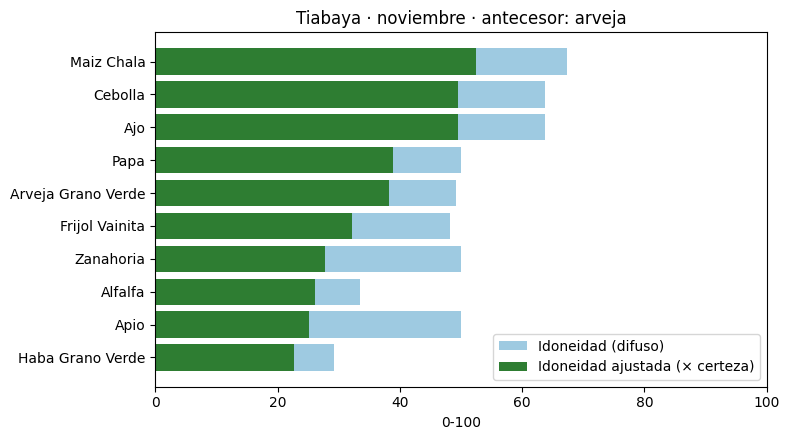

In [ ]:
import importlib, sys
sys.path.insert(0, '.')
import agropredix_motor as motor
importlib.reload(motor)
from agropredix_motor import cargar_modelo, recomendar, explicar
modelo = cargar_modelo('agropredix_modelo.json')

MES_EJ = 11
res = recomendar(modelo, 'TIABAYA', mes=MES_EJ, antecesor='Arveja Grano Verde')
tabla = pd.DataFrame([{'Puesto': r['puesto'], 'Cultivo': r['cultivo'], 'Idoneidad': r['idoneidad'],
                       'Certeza %': r['certeza_pct'], 'Idoneidad ajustada': r['idoneidad_ajustada']} for r in res])
display(tabla)

# Diagnóstico: qué tanto encaja cada cultivo con las condiciones (0 = no encaja, 1 = encaja totalmente)
diag = pd.DataFrame([{'Cultivo': r['cultivo'],
                      'Temperatura': round(r['grados']['temperatura']['adecuada'], 2),
                      'Acidez (pH)': round(r['grados']['ph']['adecuado'], 2),
                      'Tipo de suelo': round(r['grados']['textura']['adecuada'], 2),
                      'Época habitual': round(r['grados']['epoca']['tipica'], 2)} for r in res])
print('\nDiagnóstico: encaje de cada cultivo con las condiciones de Tiabaya')
display(diag)

print('\n===== TOP 3 (vista resumida) =====')
for r in res[:3]:
    print(explicar(r, modelo), '\n')
print('===== VISTA DETALLADA del puesto 1 =====')
print(explicar(res[0], modelo, detallado=True))

# certeza ante información incompleta (RF-0006)
sin_ant = recomendar(modelo, 'TIABAYA', mes=MES_EJ)
sin_ant_ph = recomendar(modelo, 'TIABAYA', mes=MES_EJ, omitir=('ph',))
print('\nCerteza del puesto 1, según los datos disponibles:')
print(f"  con todo registrado        : {res[0]['certeza_pct']:.0f}%")
print(f"  sin cultivo anterior       : {[r for r in sin_ant if r['cod'] == res[0]['cod']][0]['certeza_pct']:.0f}%")
print(f"  sin antecesor ni dato de pH: {[r for r in sin_ant_ph if r['cod'] == res[0]['cod']][0]['certeza_pct']:.0f}%")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
nom = [r['cultivo'] for r in res][::-1]
ax.barh(nom, [r['idoneidad'] for r in res][::-1], color='#9ecae1', label='Idoneidad (difuso)')
ax.barh(nom, [r['idoneidad_ajustada'] for r in res][::-1], color='#2e7d32', label='Idoneidad ajustada (× certeza)')
ax.set_xlim(0, 100); ax.set_xlabel('0-100'); ax.legend(loc='lower right')
ax.set_title(f'Tiabaya · {motor.MESES[MES_EJ - 1]} · antecesor: arveja')
plt.tight_layout(); plt.show()

## Paso 8 · Validación (OE4)
1. **Plantilla de 30 escenarios** para tu panel de 5 agrónomos: cada uno indica su **top-3** de cultivos. El notebook calcula después la coincidencia top-3 y el **kappa de Cohen**.
2. **Chequeo de coherencia** con la práctica local (SISAGRI). ⚠️ *No es la validación de la tesis*: el calendario de siembra sale de los mismos datos, así que es un chequeo de sentido común, no una prueba independiente.

In [ ]:
rng = np.random.default_rng(SEED)
nom_cat = cat['nombre'].tolist()

# ---- 1. escenarios para el panel (30 = 10 por distrito, meses repartidos) ----
filas = []
for d in DISTRITOS:
    meses = rng.permutation(np.arange(1, 13))[:10]
    for m in meses:
        ant = rng.choice(nom_cat + [None], p=[0.8 / len(nom_cat)] * len(nom_cat) + [0.2])
        e = modelo['distritos'][d]
        filas.append({'distrito': d, 'mes': int(m), 'antecesor': ant if ant else '(ninguno)',
                      'ph_estimado': round(e['ph'], 2), 'arcilla_pct': round(e['arcilla'], 1),
                      'temp_media_mes_c': round(e['clima'][str(int(m))]['temp_media'], 1)})
esc = pd.DataFrame(filas).sample(frac=1, random_state=SEED).reset_index(drop=True)
esc.insert(0, 'escenario_id', [f'E{i:02d}' for i in range(1, len(esc) + 1)])
plantilla = esc.copy()
plantilla['top3_experto'] = ''          # el agrónomo escribe: Cultivo1|Cultivo2|Cultivo3
plantilla['comentarios'] = ''
plantilla.to_csv('escenarios_panel_plantilla.csv', index=False, encoding='utf-8-sig')

# top-3 del modelo (archivo aparte, para NO sesgar al panel)
top3 = []
for r in esc.itertuples():
    ant = None if r.antecesor == '(ninguno)' else r.antecesor
    top3.append('|'.join(x['cultivo'] for x in recomendar(modelo, r.distrito, r.mes, antecesor=ant)[:3]))
pd.concat([esc, pd.Series(top3, name='top3_modelo')], axis=1).to_csv(
    'escenarios_panel_modelo.csv', index=False, encoding='utf-8-sig')
print('Guardados: escenarios_panel_plantilla.csv (para el panel) y escenarios_panel_modelo.csv (respuesta del modelo)')


def evaluar_panel(ruta_panel='escenarios_panel_plantilla.csv', ruta_modelo='escenarios_panel_modelo.csv'):
    """Compara el top-3 del panel contra el del modelo.
    - cobertura_top3: fracción promedio del top-3 del experto que el modelo también tiene en su top-3.
    - escenarios_con_>=2: % de escenarios con al menos 2 coincidencias.
    - kappa: Cohen sobre los juicios 'recomendado / no recomendado' de cada (escenario, cultivo)."""
    from sklearn.metrics import cohen_kappa_score
    p, m = pd.read_csv(ruta_panel), pd.read_csv(ruta_modelo)
    df = p[['escenario_id', 'top3_experto']].merge(m[['escenario_id', 'top3_modelo']], on='escenario_id')
    df = df[df['top3_experto'].fillna('').str.strip() != '']
    if df.empty:
        print('Aún no hay respuestas del panel en top3_experto.')
        return None
    cob, y_e, y_m = [], [], []
    for r in df.itertuples():
        e = {x.strip().lower() for x in r.top3_experto.split('|')}
        mo = {x.strip().lower() for x in r.top3_modelo.split('|')}
        cob.append(len(e & mo) / len(e))
        for c in nom_cat:
            y_e.append(int(c.lower() in e)); y_m.append(int(c.lower() in mo))
    out = {'escenarios_evaluados': len(df), 'cobertura_top3': float(np.mean(cob)),
           'escenarios_con_>=2': float(np.mean([c >= 2 / 3 for c in cob])),
           'kappa': float(cohen_kappa_score(y_e, y_m))}
    print(out)
    return out


# ---- 2. chequeo de coherencia con la práctica local (NO es la validación de la tesis) ----
real = (comp[comp['DISTRITO'].isin(DISTRITOS) & comp['COD_PRODUCTO'].isin(cat['COD_PRODUCTO'])]
        .groupby(['DISTRITO', 'MES', 'COD_PRODUCTO'])['SIEMBRA'].sum().reset_index())
cod2nom = dict(zip(cat['COD_PRODUCTO'], cat['nombre']))
sol = []
for d in DISTRITOS:
    for m in range(1, 13):
        r_ = real[(real['DISTRITO'] == d) & (real['MES'] == m) & (real['SIEMBRA'] > 0)].nlargest(3, 'SIEMBRA')
        if r_.empty:
            continue
        a = {cod2nom[c] for c in r_['COD_PRODUCTO']}
        b = {x['cultivo'] for x in recomendar(modelo, d, m)[:3]}
        sol.append(len(a & b) / len(a))
print(f'\nChequeo de coherencia: el top-3 del modelo coincide en promedio con {np.mean(sol) * 100:.0f}% '
      f'del top-3 sembrado en la práctica ({len(sol)} combinaciones distrito-mes).')
print('(Referencial: el calendario sale de los mismos datos del SISAGRI; no sustituye la validación con el panel.)')

Guardados: escenarios_panel_plantilla.csv (para el panel) y escenarios_panel_modelo.csv (respuesta del modelo)

Chequeo de coherencia: el top-3 del modelo coincide en promedio con 52% del top-3 sembrado en la práctica (36 combinaciones distrito-mes).
(Referencial: el calendario sale de los mismos datos del SISAGRI; no sustituye la validación con el panel.)


## Paso 9 · Descargar los resultados
Guarda en tu computadora: `agropredix_modelo.json`, `agropredix_motor.py` (para Flask/Django) y los archivos para el panel.

In [ ]:
salidas = ['agropredix_modelo.json', 'agropredix_motor.py', 'escenarios_panel_plantilla.csv',
           'escenarios_panel_modelo.csv', 'matriz_rotacion_borrador.csv', 'reglas_difusas_borrador.json']
salidas = [s for s in salidas if os.path.exists(s)]
for s in salidas:
    print('✔', s, f'({os.path.getsize(s) / 1024:.0f} KB)')
if IN_COLAB:
    for s in salidas:
        files.download(s)

✔ agropredix_modelo.json (31 KB)
✔ agropredix_motor.py (11 KB)
✔ escenarios_panel_plantilla.csv (1 KB)
✔ escenarios_panel_modelo.csv (2 KB)
✔ matriz_rotacion_borrador.csv (1 KB)
✔ reglas_difusas_borrador.json (2 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>